In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
file_path = "library_transactions.csv"

print("Dataset file:", file_path)

Dataset file: library_transactions.csv


In [16]:
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [18]:
display(df)

,Transaction ID,Date,User ID,Book Title,Genre,Borrowing Duration (Days),Time
0,T001,2026-01-05,U101,Python Basics,Programming,7,09:30
1,T002,2026-01-05,U102,Data Science,Technology,5,10:15
2,T003,2026-01-06,U103,Harry Potter,Fantasy,10,11:00
3,T004,2026-01-07,U101,Python Basics,Programming,4,14:30
4,T005,2026-01-08,U104,The Alchemist,Fiction,6,16:00
5,T006,2026-01-12,U105,Atomic Habits,Self Help,8,09:00
6,T007,2026-01-15,U106,Rich Dad Poor Dad,Finance,5,12:30
7,T008,2026-01-18,U107,Ikigai,Self Help,4,15:00
8,T009,2026-01-20,U108,Deep Work,Productivity,7,10:45
9,T010,2026-01-25,U109,The Hobbit,Fantasy,9,13:15


In [19]:
print("Total transactions:", len(df))

Total transactions: 30


In [20]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['Transaction ID', 'Date', 'User ID', 'Book Title', 'Genre', 'Borrowing Duration (Days)', 'Time']


In [22]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Transaction ID             30 non-null     str  
 1   Date                       30 non-null     str  
 2   User ID                    30 non-null     str  
 3   Book Title                 30 non-null     str  
 4   Genre                      30 non-null     str  
 5   Borrowing Duration (Days)  30 non-null     int64
 6   Time                       30 non-null     str  
dtypes: int64(1), str(6)
memory usage: 1.8 KB


In [23]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
Transaction ID               0
Date                         0
User ID                      0
Book Title                   0
Genre                        0
Borrowing Duration (Days)    0
Time                         0
dtype: int64


In [24]:
print("Duplicate transactions:", df["Transaction ID"].duplicated().sum())

Duplicate transactions: 0


In [25]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [26]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Date conversion completed.")
print("Invalid dates:", df["Date"].isna().sum())

Date conversion completed.
Invalid dates: 0


In [27]:
df["Borrowing Duration (Days)"] = pd.to_numeric(
df["Borrowing Duration (Days)"], errors="coerce"
)

invalid_duration = df["Borrowing Duration (Days)"].isna().sum()
negative_duration = (df["Borrowing Duration (Days)"] < 0).sum()

print("Invalid borrowing durations:", invalid_duration)
print("Negative borrowing durations:", negative_duration)

Invalid borrowing durations: 0
Negative borrowing durations: 0


In [28]:
rows_before = len(df)

df = df.dropna(subset=[
"Transaction ID",
"Date",
"User ID",
"Book Title",
"Genre",
"Borrowing Duration (Days)",
"Time"
])

df = df.drop_duplicates(subset=["Transaction ID"])

df = df[df["Borrowing Duration (Days)"] >= 0]

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))

Rows before cleaning: 30
Rows after cleaning: 30
Rows removed: 0


In [64]:
class LibraryDashboard:
    def __init__(self, file_path):
        self.file_path = file_path
        self.df = pd.DataFrame()
        self.statistics = {}

    def load_data(self):
        try:
            self.df = pd.read_csv(self.file_path)

            required_columns = [
                "Transaction ID",
                "Date",
                "User ID",
                "Book Title",
                "Genre",
                "Borrowing Duration (Days)",
                "Time"
            ]

            for column in required_columns:
                if column not in self.df.columns:
                    print("Missing required column:", column)
                    return False

            self.df["Date"] = pd.to_datetime(
                self.df["Date"], errors="coerce"
            )

            self.df["Borrowing Duration (Days)"] = pd.to_numeric(
                self.df["Borrowing Duration (Days)"],
                errors="coerce"
            )

            self.df = self.df.dropna(subset=required_columns)
            self.df = self.df.drop_duplicates(
                subset=["Transaction ID"]
            )
            self.df = self.df[
                self.df["Borrowing Duration (Days)"] >= 0
            ]

            print("Data loaded and validated successfully!")
            print("Total valid transactions:", len(self.df))

            return True

        except FileNotFoundError:
            print("Error: CSV file not found.")
            return False

    def calculate_statistics(self):
        self.statistics = {"Total Transactions": len(self.df),
            "Unique Users": self.df["User ID"].nunique(),
            "Unique Books": self.df["Book Title"].nunique(),
            "Average Borrowing Duration": self.df["Borrowing Duration (Days)"].mean(),
            "Top 5 Borrowed Books": self.df["Book Title"].value_counts().head(5)}

        print("Library Statistics:")
        for key, value in self.statistics.items():
            print(f"{key}:")
            print(value)

    def generate_report(self):
        print("E-Library Data Analysis Report")
        print("-" * 35)
        print("Total Transactions:", len(self.df))
        print("Unique Users:", self.df["User ID"].nunique())
        print("Unique Books:", self.df["Book Title"].nunique())
        print("Average Borrowing Duration:",
              self.df["Borrowing Duration (Days)"].mean())
        print("\nTop 5 Borrowed Books:")
        print(self.df["Book Title"].value_counts().head(5))

In [65]:
library = LibraryDashboard("library_transactions.csv")
print("LibraryDashboard object created successfully.")


LibraryDashboard object created successfully.


In [66]:
library.load_data()
library.calculate_statistics()
library.generate_report()

Data loaded and validated successfully!
Total valid transactions: 30
Library Statistics:
Total Transactions:
30
Unique Users:
11
Unique Books:
9
Average Borrowing Duration:
6.2
Top 5 Borrowed Books:
Book Title
Python Basics    5
Data Science     4
Harry Potter     3
The Alchemist    3
Atomic Habits    3
Name: count, dtype: int64
E-Library Data Analysis Report
-----------------------------------
Total Transactions: 30
Unique Users: 11
Unique Books: 9
Average Borrowing Duration: 6.2

Top 5 Borrowed Books:
Book Title
Python Basics    5
Data Science     4
Harry Potter     3
The Alchemist    3
Atomic Habits    3
Name: count, dtype: int64


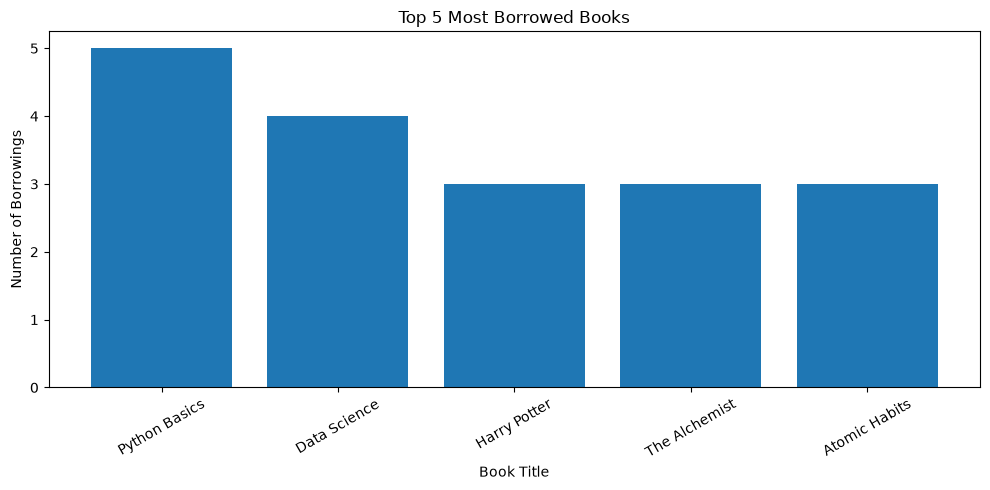

In [54]:
plt.figure(figsize=(10, 5))

top_books = library.df["Book Title"].value_counts().head(5)

plt.bar(top_books.index, top_books.values)

plt.title("Top 5 Most Borrowed Books")
plt.xlabel("Book Title")
plt.ylabel("Number of Borrowings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

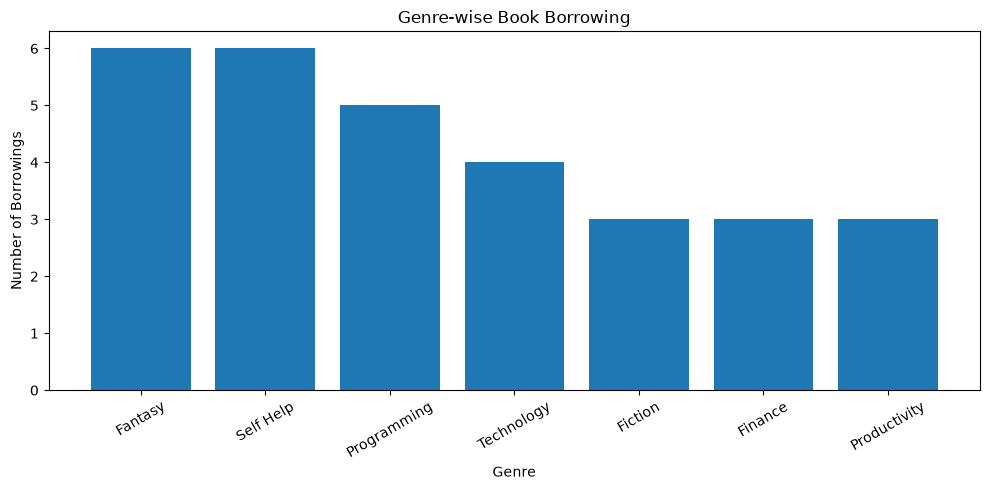

In [55]:
genre_counts = library.df["Genre"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(genre_counts.index, genre_counts.values)

plt.title("Genre-wise Book Borrowing")
plt.xlabel("Genre")
plt.ylabel("Number of Borrowings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

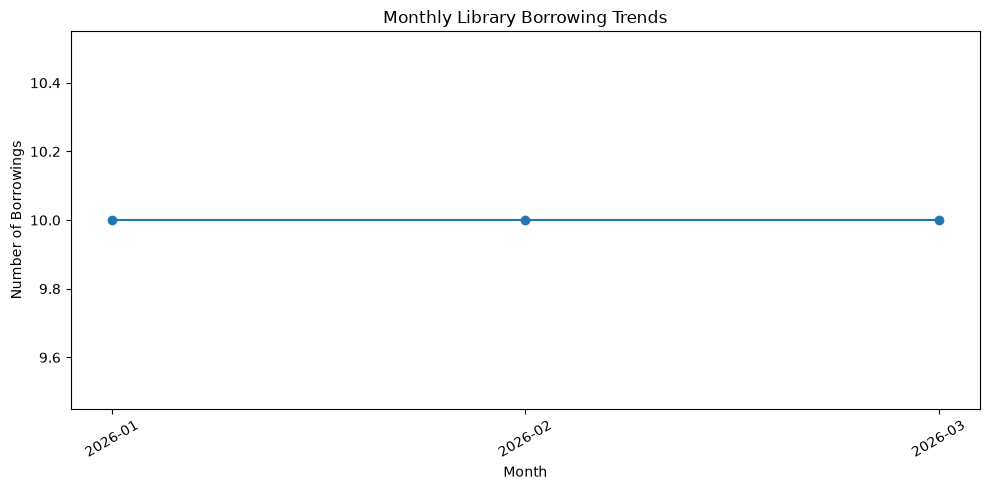

In [57]:
monthly_borrowing = library.df.copy()

monthly_borrowing["Month"] = (
    monthly_borrowing["Date"].dt.to_period("M")
)

monthly_counts = monthly_borrowing.groupby("Month").size()

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_counts.index.astype(str),
    monthly_counts.values,
    marker="o"
)

plt.title("Monthly Library Borrowing Trends")
plt.xlabel("Month")
plt.ylabel("Number of Borrowings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

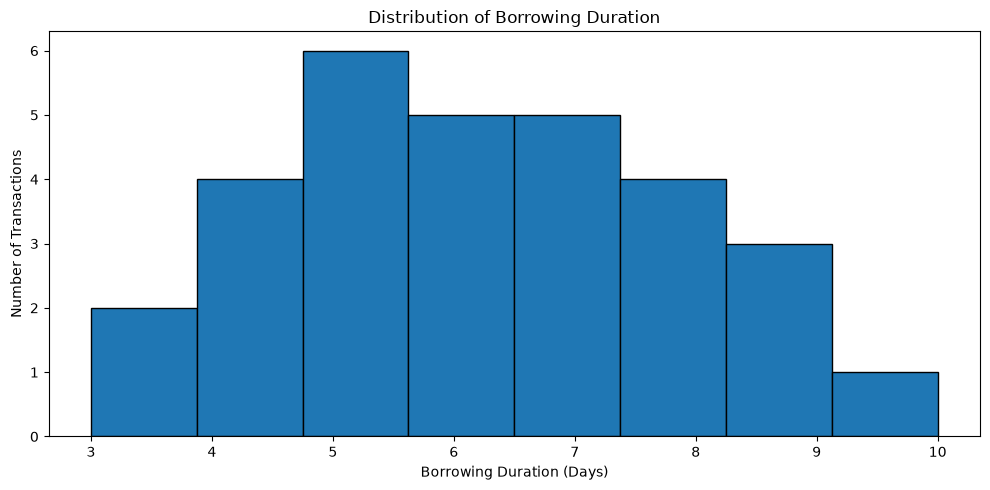

In [58]:
plt.figure(figsize=(10, 5))

plt.hist(
    library.df["Borrowing Duration (Days)"],
    bins=8,
    edgecolor="black"
)

plt.title("Distribution of Borrowing Duration")
plt.xlabel("Borrowing Duration (Days)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [60]:
# Filter transactions by genre
def filter_transactions(self, genre=None, start_date=None, end_date=None):
    filtered_data = self.df.copy()

    if genre is not None:
        filtered_data = filtered_data[filtered_data["Genre"] == genre]

    if start_date is not None:
        filtered_data = filtered_data[filtered_data["Date"] >= start_date]

    if end_date is not None:
        filtered_data = filtered_data[filtered_data["Date"] <= end_date]

    return filtered_data

In [61]:
library.df["Genre"].unique

<bound method Series.unique of 0      Programming
1       Technology
2          Fantasy
3      Programming
4          Fiction
5        Self Help
6          Finance
7        Self Help
8     Productivity
9          Fantasy
10      Technology
11         Fantasy
12     Programming
13         Fiction
14       Self Help
15    Productivity
16         Finance
17       Self Help
18         Fantasy
19     Programming
20     Programming
21         Fantasy
22      Technology
23         Fiction
24       Self Help
25    Productivity
26         Finance
27       Self Help
28         Fantasy
29      Technology
Name: Genre, dtype: str>

In [62]:
filtered_data = library.df[library.df["Genre"] == "Fantasy"]

print("Fantasy book transactions:")
print(filtered_data[["Book Title", "Genre"]])
print("Total transactions:", len(filtered_data))

Fantasy book transactions:
      Book Title    Genre
2   Harry Potter  Fantasy
9     The Hobbit  Fantasy
11  Harry Potter  Fantasy
18    The Hobbit  Fantasy
21  Harry Potter  Fantasy
28    The Hobbit  Fantasy
Total transactions: 6


In [67]:
library.generate_report()

E-Library Data Analysis Report
-----------------------------------
Total Transactions: 30
Unique Users: 11
Unique Books: 9
Average Borrowing Duration: 6.2

Top 5 Borrowed Books:
Book Title
Python Basics    5
Data Science     4
Harry Potter     3
The Alchemist    3
Atomic Habits    3
Name: count, dtype: int64
